# Horas trabajadas y productividad por hora

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "horas-productividad"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Horas trabajadas y productividad por hora"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ocde"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Horas trabajadas al año por ocupado", "unidad": "horas al año"}
EJE_Y = {"titulo": "PIB por hora trabajada", "unidad": "dólares PPA por hora, precios corrientes"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la OCDE con dato en los dos ejes.

- **Eje horizontal:** las **horas efectivamente trabajadas al año por persona ocupada** (asalariados y autónomos), según la OCDE.
- **Eje vertical:** el **PIB por hora trabajada**, en dólares con la misma capacidad de compra (PPA) a precios corrientes del mismo año, el nivel que es comparable entre países en un año.

**Para qué sirve.** Pone juntas la duración del trabajo y la productividad por hora, los dos datos del debate sobre la reducción de la jornada: quienes la proponen sostienen que trabajar menos horas no reduce lo producido o eleva la productividad por hora; quienes la rechazan sostienen que la productividad debe subir antes. **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- La OCDE advierte de que las horas anuales no son del todo comparables entre países, porque proceden de fuentes distintas; sirven mejor para comparar la evolución de un país.
- Más horas por ocupado no implican más horas por habitante: depende también de cuántas personas trabajan.
- Cada punto usa el último año en que el país tiene dato en los dos ejes.

## 2. Descarga

- **OCDE, horas trabajadas** (`OECD.ELS.SAE,DSD_HW@DF_AVG_ANN_HRS_WKD`, versión 1.0): media de horas efectivas (`ACTUAL`) al año por persona ocupada (`EMP`), todos los ocupados (`_T`).
- **OCDE, base de datos de productividad** (`OECD.SDD.TPS,DSD_PDB@DF_PDB`, versión 2.0): PIB por hora trabajada (`GDPHRS`), total de actividades, en dólares PPA a precios corrientes (`USD_PPP_H`, `V`). El dataflow `DF_PDB_LV` que cita el config ya no responde y se usa su sucesor `DF_PDB`, como en las gráficas de economía.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import oecd
from lib.tipos import FuenteMeta

AREAS = {c: c for c in PAISES}  # todos los países del universo, con su código como clave de serie
HOY = date.today().isoformat()

# Horas efectivas al año por ocupado (OCDE). El dataflow no tiene dimensión de frecuencia.
DATAFLOW_HRS = "OECD.ELS.SAE,DSD_HW@DF_AVG_ANN_HRS_WKD,1.0"
# Dimensiones: país . medida . unidad . sexo . edad . situación . periodo . tipo de horas . situación profesional
#              . jornada . operación . tramos de horas . empleo
CLAVE_HRS = "{AREA}.HW.H_Y_PS._Z._Z.EMP.A.ACTUAL._T._Z.MEAN._Z._T"
# PIB por hora trabajada (OCDE, productividad), dólares PPA a precios corrientes
DATAFLOW_PDB = "OECD.SDD.TPS,DSD_PDB@DF_PDB,2.0"
# Dimensiones: país . frecuencia . medida . actividad . unidad . precios (V: corrientes) . transformación . activo . conversión
CLAVE_PDB = "{AREA}.A.GDPHRS._T.USD_PPP_H.V.N._Z.PPP"
AGREGADOS = {"OECD": "OECD", "EU27_2020": "EU27_2020"}

x, _ = oecd.get(DATAFLOW_HRS, CLAVE_HRS, areas={**AREAS, **AGREGADOS}, desde=DESDE)
y, _ = oecd.get(DATAFLOW_PDB, CLAVE_PDB, areas={**AREAS, **AGREGADOS}, desde=DESDE)
print("Países con horas:", x["serie"].nunique(), "· con productividad:", y["serie"].nunique())

Países con horas: 39 · con productividad: 40


## 3. Transformación

1. Los dos ejes se usan tal como los publica la OCDE, sin transformar. Se quitan los valores 0, que la OCDE usa en algunos países sin dato.
2. **Puntos de las medias:** la UE-27 y la OCDE son un punto solo si la fuente publica su agregado en los dos ejes; si falta en uno, se quita del otro.
3. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")


ceros_x = sorted(x.loc[x["valor"] <= 0, "serie"].unique())
x, y = x[x["valor"] > 0], y[y["valor"] > 0]
medias = [a for a in AGREGADOS if a in set(x["serie"]) and a in set(y["serie"])]
x = x[~x["serie"].isin(set(AGREGADOS) - set(medias))]
y = y[~y["serie"].isin(set(AGREGADOS) - set(medias))]
print("Medias con dato en los dos ejes:", medias, "· series con 0 horas:", ceros_x)

_, FLUJO_HRS, VERSION_HRS = DATAFLOW_HRS.split(",")
_, FLUJO_PDB, VERSION_PDB = DATAFLOW_PDB.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_HRS} (horas trabajadas, versión {VERSION_HRS}): HW, H_Y_PS, EMP, ACTUAL, _T", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", oecd.ORGANISMO, f"{FLUJO_PDB} (productividad, versión {VERSION_PDB}): GDPHRS, _T, USD_PPP_H, V", oecd.URL_EXPLORER, HOY),
]
NOMBRES_MEDIAS = {"OECD": "la OCDE", "EU27_2020": "la UE-27"}
NOTAS = [
    f"Horas: OCDE, horas trabajadas ({FLUJO_HRS}, versión {VERSION_HRS}): horas efectivamente trabajadas al año por "
    "persona ocupada, asalariados y autónomos. La OCDE advierte de que no son del todo comparables entre países por las "
    "diferencias de las fuentes.",
    f"Productividad: OCDE, base de datos de productividad ({FLUJO_PDB}, versión {VERSION_PDB}): PIB por hora trabajada "
    "en dólares PPA a precios corrientes del año de cada punto.",
    "Más horas por ocupado no implican más horas por habitante: depende también de cuántas personas trabajan.",
    ("Medias: " + " y ".join(NOMBRES_MEDIAS[m] for m in medias) + ", con los agregados que publica la OCDE en los dos ejes."
     if medias else "La OCDE no publica ningún agregado en los dos ejes y no hay puntos de medias."),
]
if ceros_x:
    NOTAS.append("La OCDE publica 0 horas (sin dato) para " + ", ".join(ceros_x) + ": esos años no se usan.")
for n in NOTAS:
    print("-", n)

Medias con dato en los dos ejes: ['OECD'] · series con 0 horas: []
- Horas: OCDE, horas trabajadas (DSD_HW@DF_AVG_ANN_HRS_WKD, versión 1.0): horas efectivamente trabajadas al año por persona ocupada, asalariados y autónomos. La OCDE advierte de que no son del todo comparables entre países por las diferencias de las fuentes.
- Productividad: OCDE, base de datos de productividad (DSD_PDB@DF_PDB, versión 2.0): PIB por hora trabajada en dólares PPA a precios corrientes del año de cada punto.
- Más horas por ocupado no implican más horas por habitante: depende también de cuántas personas trabajan.
- Medias: la OCDE, con los agregados que publica la OCDE en los dos ejes.


## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

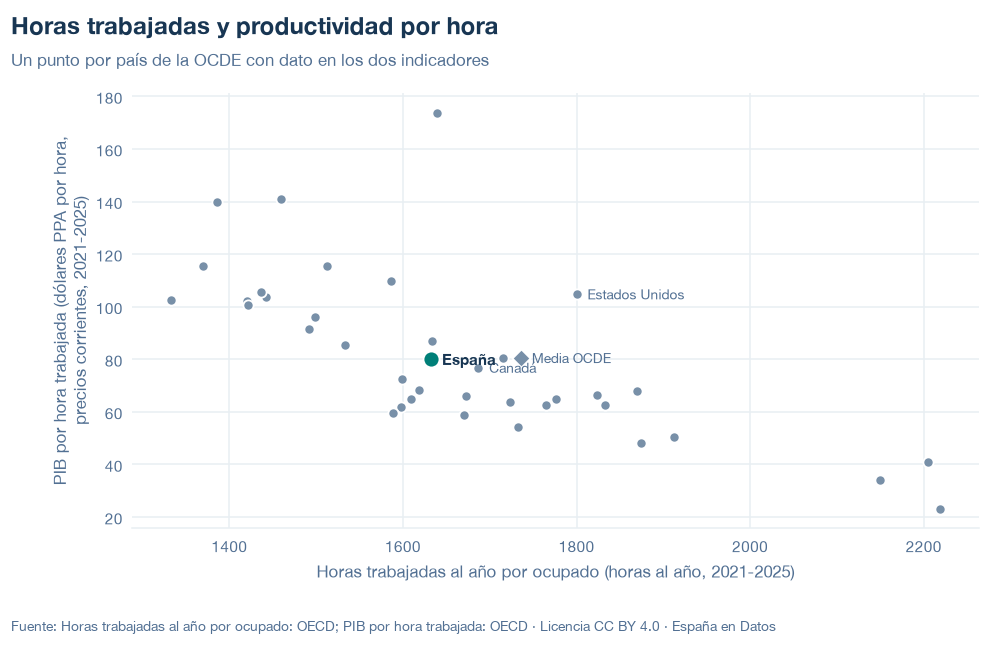

codigo  anio           x          y
   AUS  2025 1633.000000  86.850922
   AUT  2025 1442.206000 103.889055
   BEL  2025 1586.000000 109.727662
   CAN  2025 1687.000000  76.813445
   CHE  2025 1512.249000 115.345606
   CHL  2025 1912.000000  50.575770
   COL  2024 2219.261000  23.213392
   CRI  2024 2149.000000  34.008622
   CZE  2025 1823.628000  66.505529
   DEU  2025 1332.200000 102.687143
   DNK  2025 1369.337000 115.334073
   ESP  2025 1632.700000  80.060118
   EST  2025 1609.700000  64.738254
   FIN  2025 1491.905000  91.627339
   FRA  2025 1498.293000  96.052272
   GBR  2025 1532.915000  85.562892
   GRC  2025 1874.319000  48.123024
   HUN  2025 1670.694000  58.989059
   IRL  2025 1638.974000 173.858222
   ISL  2025 1420.837000 102.081119
   ISR  2025 1870.000000  68.131094
   ITA  2025 1715.700000  80.363171
   JPN  2025 1597.507000  61.773697
   KOR  2025 1833.000000  62.459219
   LTU  2025 1673.062000  65.973733
   LUX  2025 1459.000000 141.136989
   LVA  2025 1588.149000  59

In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/horas-productividad.json y data/horas-productividad.csv


## 6. Fuentes, notas y licencia

- OCDE, horas trabajadas: `OECD.ELS.SAE,DSD_HW@DF_AVG_ANN_HRS_WKD,1.0` (`HW`, `H_Y_PS`, `EMP`, `A`, `ACTUAL`, `_T`, `MEAN`).
- OCDE, base de datos de productividad: `OECD.SDD.TPS,DSD_PDB@DF_PDB,2.0` (`GDPHRS`, `_T`, `USD_PPP_H`, `V`, `N`, `_Z`, `PPP`).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.